# A5 — Bootstrap + Heterogeneous Ensembles + Stacking (Regression + Classification)

In [14]:
import os
import json
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd

import mlflow
import mlflow.sklearn

from scipy.stats import ttest_rel

from dotenv import load_dotenv, find_dotenv

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, balanced_accuracy_score, f1_score, log_loss
)

from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import StackingRegressor, StackingClassifier

# Optional: silence noisy warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="mlflow")

# Optional TLS warning suppression (if you have self-signed certs on MLflow server)
try:
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
except Exception:
    pass

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Store per-bootstrap metrics for paired t-tests
reg_metrics_by_boot: Dict[int, Dict[str, Dict[str, float]]] = {}
# structure:
# reg_metrics_by_boot[b][method_name][metric_name] = value

In [2]:
# Notebook location: ml/models/research/A5/<something>/
SCORES_PATH = Path("../../data/processed/20190108_scores_and_weak_links.csv")
FEATURES_PATH = Path("../../data/processed/AimoScore_WeakLink_big_scores.csv")
REG_PATH = Path("../../data/raw/AimoScore_WeakLink_big_scores.xls")

scores = pd.read_csv(SCORES_PATH)
big = pd.read_csv(FEATURES_PATH)
df_reg = pd.read_excel(REG_PATH)

print("scores:", scores.shape)
print("big:", big.shape)
print("regression:", df_reg.shape)

# VSCode notebook usually supports display(), but if not, replace with print(df.head())
display(scores.head(2))
display(big.head(2))
display(df_reg.head(2))

scores: (2096, 17)
big: (2094, 43)
regression: (2094, 43)


,ID,Date,SCORE,ForwardHead,LeftArmFallForward,RightArmFallForward,LeftShoulderElevation,RightShoulderElevation,ExcessiveForwardLean,LeftAsymmetricalWeightShift,RightAsymmetricalWeightShift,LeftKneeMovesInward,RightKneeMovesInward,LeftKneeMovesOutward,RightKneeMovesOutward,LeftHeelRises,RightHeelRises
0,cf0e95ab-d6ec-475a-9cc0-c9444b8dd080.Kinect,2018-07-19,0.612532,0.31,1.34,1.15,0.33,0.49,0.00,0.0,0.08,0.0,0.0,0.0,0.77,0.0,0.0
1,6210cc6d-575d-4e9f-bab1-4fe1da2a30a3.Kinect,2018-07-30,0.388809,1.49,1.42,1.39,0.00,0.00,1.08,0.1,0.00,0.0,0.0,0.0,0.40,0.0,0.0


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,...,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.52176,0.457198,...,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.52176,0.729316,...,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,...,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.52176,0.457198,...,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.52176,0.729316,...,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect


In [3]:
import mlflow
import mlflow.sklearn
from dotenv import load_dotenv
from os import getenv

# Adjust this path to where your env file truly is.
# If your file is named ".env" in repo root, use: load_dotenv("../../../../.env")
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix your env path or env variable.")

EXPERIMENT_NAME = "A5_bootstrap_hetero_stacking"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A5_bootstrap_hetero_stacking


### Utilities (bootstrap + metrics)

In [4]:
from typing import Dict, List, Tuple
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, balanced_accuracy_score, f1_score, log_loss
)

def make_bootstrap_indices(n: int, seed: int) -> np.ndarray:
    """Bootstrap indices (with replacement), size n."""
    rng = np.random.default_rng(seed)
    return rng.integers(low=0, high=n, size=n, endpoint=False)

def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": rmse(y_true, y_pred),
        "mae": float(mean_absolute_error(y_true, y_pred)),
    }

def classification_metrics(y_true, y_pred, y_proba=None, classes=None) -> Dict[str, float]:
    m = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }
    if y_proba is not None and classes is not None:
        m["log_loss"] = float(log_loss(y_true, y_proba, labels=list(classes)))
    return m

## REGRESSION: Bootstrap + Heterogeneous + Stacking

### Regression dataset prep

In [5]:
# Target
y_reg = df_reg["AimoScore"].astype(float)

# Features: drop non-features
X_reg = df_reg.drop(columns=["AimoScore", "EstimatedScore", "ID"], errors="ignore")
X_reg = X_reg.apply(pd.to_numeric, errors="coerce")

print("X_reg:", X_reg.shape, "y_reg:", y_reg.shape)
print("Missing cells:", int(X_reg.isna().sum().sum()))
display(X_reg.head(2))

X_reg: (2094, 40) y_reg: (2094,)
Missing cells: 0


,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,No_10_Angle_Deviation,...,No_18_NASM_Deviation,No_19_NASM_Deviation,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation
0,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.52176,0.457198,0.210426,...,0.587757,0.833094,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747
1,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.52176,0.729316,0.912482,...,0.441416,0.670971,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207


### Regression split + heterogeneous base models

In [34]:
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_SEED
)

print("Train:", X_train_r.shape, "Test:", X_test_r.shape)

# Target transform (useful if AimoScore is in (0,1))
def logit(y, eps=1e-6):
    y = np.clip(y, eps, 1 - eps)
    return np.log(y / (1 - y))

def inv_logit(z):
    return 1 / (1 + np.exp(-z))

USE_LOGIT_TARGET = True

def maybe_logit(reg):
    if not USE_LOGIT_TARGET:
        return reg
    return TransformedTargetRegressor(
        regressor=reg,
        func=logit,
        inverse_func=inv_logit
    )


# Heterogeneous regression models
regressors = {
    "linreg": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LinearRegression())
    ]),
    "ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=RANDOM_SEED))
    ]),
    "rf": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1
        ))
    ]),

    # --- Boosting (scikit-learn, safe to add) ---
    "gbr": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", maybe_logit(GradientBoostingRegressor(random_state=RANDOM_SEED)))
    ]),
    "hgb": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", maybe_logit(HistGradientBoostingRegressor(random_state=RANDOM_SEED)))
    ]),
}

# --- Optional: add XGBoost / LightGBM if installed ---
try:
    from xgboost import XGBRegressor
    regressors["xgb"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", maybe_logit(XGBRegressor(
            random_state=RANDOM_SEED,
            n_estimators=1200,
            learning_rate=0.03,
            max_depth=6,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=1.0,
            objective="reg:squarederror",
            tree_method="hist",
            n_jobs=-1,
        )))
    ])
except Exception:
    pass

try:
    from lightgbm import LGBMRegressor
    regressors["lgbm"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", maybe_logit(LGBMRegressor(
            random_state=RANDOM_SEED,
            n_estimators=2000,
            learning_rate=0.03,
            num_leaves=127,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=1.0,
            n_jobs=-1
        )))
    ])
except Exception:
    pass

N_BOOTSTRAPS_R = 10
BOOTSTRAP_SEED0_R = 10_000

Train: (1675, 40) Test: (419, 40)


### Regression: bootstrap training for all base models + MLflow logging

In [35]:
# Store per-bootstrap metrics for paired t-tests
reg_metrics_by_boot: Dict[int, Dict[str, Dict[str, float]]] = {}

# store all base model predictions across all bootstraps/models for "global mean ensemble"
all_test_preds_r: List[np.ndarray] = []

with mlflow.start_run(run_name="REG_parent") as parent_run:
    mlflow.log_params({
        "task": "regression",
        "random_seed": RANDOM_SEED,
        "n_bootstraps": N_BOOTSTRAPS_R,
        "bootstrap_seed0": BOOTSTRAP_SEED0_R,
        "n_model_types": len(regressors),
        "train_size": int(X_train_r.shape[0]),
        "test_size": int(X_test_r.shape[0]),
        "n_features": int(X_train_r.shape[1]),
    })

    for b in range(N_BOOTSTRAPS_R):
        seed = BOOTSTRAP_SEED0_R + b
        n_train = X_train_r.shape[0]

        boot_idx = make_bootstrap_indices(n_train, seed=seed)
        Xb = X_train_r.iloc[boot_idx]
        yb = y_train_r.iloc[boot_idx]

        # temporary predictions for per-bootstrap ensemble
        boot_preds: List[np.ndarray] = []

        # --- train base models ---
        for model_name, base in regressors.items():
            m = clone(base)

            with mlflow.start_run(run_name=f"REG_boot{b:03d}_{model_name}", nested=True):
                mlflow.log_params({
                    "bootstrap_id": b,
                    "bootstrap_seed": seed,
                    "model_name": model_name,
                    "bootstrap_unique_count": int(len(np.unique(boot_idx))),
                })

                m.fit(Xb, yb)
                yhat = m.predict(X_test_r)

                boot_preds.append(yhat)
                all_test_preds_r.append(yhat)

                mets = regression_metrics(y_test_r, yhat)

                reg_metrics_by_boot.setdefault(b, {})
                reg_metrics_by_boot[b][model_name] = mets

                for k, v in mets.items():
                    mlflow.log_metric(f"test_{k}", v)

                mlflow.sklearn.log_model(m, name="model")

        # --- per-bootstrap ensemble mean (across model types for THIS bootstrap) ---
        yhat_boot_ens = np.mean(np.vstack(boot_preds), axis=0)
        ens_mets = regression_metrics(y_test_r, yhat_boot_ens)
        reg_metrics_by_boot[b]["ens_mean_in_boot"] = ens_mets

        with mlflow.start_run(run_name=f"REG_boot{b:03d}_ensemble_mean", nested=True):
            mlflow.log_params({
                "bootstrap_id": b,
                "bootstrap_seed": seed,
                "ensemble_type": "mean_across_model_types_in_bootstrap",
            })
            for k, v in ens_mets.items():
                mlflow.log_metric(f"test_{k}", v)

        # --- per-bootstrap stacking (trained on THIS bootstrap sample) ---
        estimators_r = [(name, clone(model)) for name, model in regressors.items()]
        stack_r = StackingRegressor(
            estimators=estimators_r,
            final_estimator=Ridge(alpha=1.0, random_state=RANDOM_SEED),
            cv=5,
            n_jobs=-1
        )

        with mlflow.start_run(run_name=f"REG_boot{b:03d}_stacking", nested=True):
            mlflow.log_params({
                "bootstrap_id": b,
                "bootstrap_seed": seed,
                "model_name": "stacking_in_boot",
                "stack_cv": 5
            })

            stack_r.fit(Xb, yb)
            yhat_stack = stack_r.predict(X_test_r)
            stack_mets = regression_metrics(y_test_r, yhat_stack)

            reg_metrics_by_boot[b]["stacking_in_boot"] = stack_mets

            for k, v in stack_mets.items():
                mlflow.log_metric(f"test_{k}", v)

            mlflow.sklearn.log_model(stack_r, name="model")

    # --- global ensemble across ALL trained base models (all bootstraps, all model types) ---
    yhat_global_mean = np.mean(np.vstack(all_test_preds_r), axis=0)
    global_mean_mets = regression_metrics(y_test_r, yhat_global_mean)

    with mlflow.start_run(run_name="REG_ensemble_mean_global", nested=True):
        mlflow.log_params({"ensemble_type": "mean_over_all_bootstrap_models"})
        for k, v in global_mean_mets.items():
            mlflow.log_metric(f"test_{k}", v)

    print("REG parent run:", parent_run.info.run_id)
    print("REG global mean ensemble metrics:", global_mean_mets)

🏃 View run REG_boot000_linreg at: https://172.27.62.170:5001/#/experiments/7/runs/9b084ea07d434a298f9573fbd80a4f23
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run REG_boot000_ridge at: https://172.27.62.170:5001/#/experiments/7/runs/aa78224b4e254455ba34ca2865bdc23d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run REG_boot000_rf at: https://172.27.62.170:5001/#/experiments/7/runs/dc926b1560e848d6b86a0c8f4b1c7fe4
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run REG_boot000_gbr at: https://172.27.62.170:5001/#/experiments/7/runs/ebb7fd65803c4bc5a9bbf077fabdf637
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run REG_boot000_hgb at: https://172.27.62.170:5001/#/experiments/7/runs/4f7f7de82f684bcaa6385ecfff8e4eb4
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run REG_boot000_ensemble_mean at: https://172.27.62.170:5001/#/experiments/7/runs/d5d14ffeebc44b419fe2b6

### Regression: stacking challenger

In [23]:

estimators_r = [(name, clone(model)) for name, model in regressors.items()]

stack_r = StackingRegressor(
    estimators=estimators_r,
    final_estimator=Ridge(alpha=1.0, random_state=RANDOM_SEED),
    cv=5,
    n_jobs=-1
)

with mlflow.start_run(run_name="REG_stacking", nested=True):
    stack_r.fit(X_train_r, y_train_r)
    yhat_stack = stack_r.predict(X_test_r)
    mets = regression_metrics(y_test_r, yhat_stack)

    for k, v in mets.items():
        mlflow.log_metric(f"test_{k}", v)

    mlflow.sklearn.log_model(stack_r, name="model")

print("REG stacking metrics:", mets)

🏃 View run REG_stacking at: https://172.27.62.170:5001/#/experiments/7/runs/5629e00ba8df48d984b4b515f0ffad1f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
REG stacking metrics: {'r2': 0.7434938092717926, 'rmse': 0.1237548104234389, 'mae': 0.09084878027500844}


## CLASSIFICATION: Bootstrap + Heterogeneous + Stacking

In [24]:
# --- Classification: Predict WeakestLink ---
NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

DROP_CLASSES = True
DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightAsymmetricalWeightShift",
}
DROP_TIES = True

if DROP_CLASSES:
    indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]

scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
ties = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)
scores["HasTie"] = ties

scores_labeled = scores.loc[~scores["HasTie"]].copy() if DROP_TIES else scores.copy()
scores_labeled = scores_labeled.dropna(subset=["WeakestLink"])

labels = scores_labeled[["ID", "WeakestLink"]]
data = big.merge(labels, on="ID", how="inner")

angle_cols = [c for c in data.columns if c.startswith("No_") and c.endswith("_Angle_Deviation")]
nasm_cols  = [c for c in data.columns if c.startswith("No_") and c.endswith("_NASM_Deviation")]
feature_cols = sorted(angle_cols) + sorted(nasm_cols)

X_clf = data[feature_cols].apply(pd.to_numeric, errors="coerce")
y_clf = data["WeakestLink"].astype(str)

mask = X_clf.notna().all(axis=1)
X_clf = X_clf.loc[mask].reset_index(drop=True)
y_clf = y_clf.loc[mask].reset_index(drop=True)

classes_clf = np.array(sorted(y_clf.unique()), dtype=object)

print("X_clf:", X_clf.shape, "y_clf:", y_clf.shape, "n_classes:", len(classes_clf))
print("Top class counts:\n", y_clf.value_counts().head(10))

X_clf: (1728, 38) y_clf: (1728,) n_classes: 11
Top class counts:
 WeakestLink
RightArmFallForward            454
LeftArmFallForward             328
RightKneeMovesOutward          278
RightShoulderElevation         252
ExcessiveForwardLean            99
ForwardHead                     96
LeftAsymmetricalWeightShift     71
LeftShoulderElevation           51
LeftKneeMovesOutward            49
RightKneeMovesInward            46
Name: count, dtype: int64


### Classification split + heterogeneous models

In [25]:

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_SEED, stratify=y_clf
)

classifiers = {
    "logreg": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_SEED))
    ]),
    "lda": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LinearDiscriminantAnalysis())
    ]),
    "knn": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15))
    ]),
    "rf": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1))
    ]),
}

N_BOOTSTRAPS_C = 10
BOOTSTRAP_SEED0_C = 20_000

print("Train:", X_train_c.shape, "Test:", X_test_c.shape)

Train: (1382, 38) Test: (346, 38)


### Classification stacking challenger

In [26]:
# Store per-bootstrap metrics for paired t-tests
clf_metrics_by_boot: Dict[int, Dict[str, Dict[str, float]]] = {}

# store all model probas across all bootstraps/models for "global mean proba ensemble"
all_test_proba_c: List[np.ndarray] = []

with mlflow.start_run(run_name="CLF_parent") as parent_run:
    mlflow.log_params({
        "task": "classification",
        "random_seed": RANDOM_SEED,
        "n_bootstraps": N_BOOTSTRAPS_C,
        "bootstrap_seed0": BOOTSTRAP_SEED0_C,
        "n_model_types": len(classifiers),
        "train_size": int(X_train_c.shape[0]),
        "test_size": int(X_test_c.shape[0]),
        "n_features": int(X_train_c.shape[1]),
        "drop_ties": DROP_TIES,
        "drop_classes": DROP_CLASSES,
        "n_classes": int(len(classes_clf)),
    })

    for b in range(N_BOOTSTRAPS_C):
        seed = BOOTSTRAP_SEED0_C + b
        n_train = X_train_c.shape[0]

        boot_idx = make_bootstrap_indices(n_train, seed=seed)
        Xb = X_train_c.iloc[boot_idx]
        yb = y_train_c.iloc[boot_idx]

        # temporary probas for per-bootstrap ensemble
        boot_probas: List[np.ndarray] = []

        # --- train base models ---
        for model_name, base in classifiers.items():
            m = clone(base)

            with mlflow.start_run(run_name=f"CLF_boot{b:03d}_{model_name}", nested=True):
                mlflow.log_params({
                    "bootstrap_id": b,
                    "bootstrap_seed": seed,
                    "model_name": model_name,
                    "bootstrap_unique_count": int(len(np.unique(boot_idx))),
                })

                m.fit(Xb, yb)
                yhat = m.predict(X_test_c)
                proba = m.predict_proba(X_test_c)

                boot_probas.append(proba)
                all_test_proba_c.append(proba)

                classes_for_loss = getattr(m, "classes_", classes_clf)
                mets = classification_metrics(y_test_c, yhat, proba, classes=classes_for_loss)

                clf_metrics_by_boot.setdefault(b, {})
                clf_metrics_by_boot[b][model_name] = mets

                for k, v in mets.items():
                    mlflow.log_metric(f"test_{k}", v)

                mlflow.sklearn.log_model(m, name="model")

        # --- per-bootstrap ensemble (mean probas across model types for THIS bootstrap) ---
        proba_boot_ens = np.mean(np.stack(boot_probas, axis=0), axis=0)
        yhat_boot_ens = classes_clf[np.argmax(proba_boot_ens, axis=1)]

        ens_mets = classification_metrics(y_test_c, yhat_boot_ens, proba_boot_ens, classes=classes_clf)
        clf_metrics_by_boot[b]["ens_proba_mean_in_boot"] = ens_mets

        with mlflow.start_run(run_name=f"CLF_boot{b:03d}_ensemble_proba_mean", nested=True):
            mlflow.log_params({
                "bootstrap_id": b,
                "bootstrap_seed": seed,
                "ensemble_type": "mean_proba_across_model_types_in_bootstrap",
            })
            for k, v in ens_mets.items():
                mlflow.log_metric(f"test_{k}", v)

        # --- per-bootstrap stacking (trained on THIS bootstrap sample) ---
        estimators_c = [(name, clone(model)) for name, model in classifiers.items()]
        stack_c = StackingClassifier(
            estimators=estimators_c,
            final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_SEED),
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED),
            n_jobs=-1,
            stack_method="predict_proba",
            passthrough=False
        )

        with mlflow.start_run(run_name=f"CLF_boot{b:03d}_stacking", nested=True):
            mlflow.log_params({
                "bootstrap_id": b,
                "bootstrap_seed": seed,
                "model_name": "stacking_in_boot",
                "stack_cv": 5
            })

            stack_c.fit(Xb, yb)
            yhat_stack = stack_c.predict(X_test_c)
            proba_stack = stack_c.predict_proba(X_test_c)

            stack_mets = classification_metrics(y_test_c, yhat_stack, proba_stack, classes=stack_c.classes_)
            clf_metrics_by_boot[b]["stacking_in_boot"] = stack_mets

            for k, v in stack_mets.items():
                mlflow.log_metric(f"test_{k}", v)

            mlflow.sklearn.log_model(stack_c, name="model")

    # --- global ensemble across ALL trained base models (all bootstraps, all model types) ---
    proba_global_mean = np.mean(np.stack(all_test_proba_c, axis=0), axis=0)
    yhat_global = classes_clf[np.argmax(proba_global_mean, axis=1)]
    global_mets = classification_metrics(y_test_c, yhat_global, proba_global_mean, classes=classes_clf)

    with mlflow.start_run(run_name="CLF_ensemble_proba_mean_global", nested=True):
        mlflow.log_params({"ensemble_type": "mean_proba_over_all_bootstrap_models"})
        for k, v in global_mets.items():
            mlflow.log_metric(f"test_{k}", v)

    print("CLF parent run:", parent_run.info.run_id)
    print("CLF global proba-mean ensemble metrics:", global_mets)

🏃 View run CLF_boot000_logreg at: https://172.27.62.170:5001/#/experiments/7/runs/6f35cbdfdb7c4b23af6d56ab67407f26
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run CLF_boot000_lda at: https://172.27.62.170:5001/#/experiments/7/runs/f28695e8c7bc4230b75f956e8f869c92
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run CLF_boot000_knn at: https://172.27.62.170:5001/#/experiments/7/runs/2e56d9dbf62844d981bc2d15a7b06424
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run CLF_boot000_rf at: https://172.27.62.170:5001/#/experiments/7/runs/0257d288c37c4a3d84c1a030bf5be21a
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run CLF_boot000_ensemble_proba_mean at: https://172.27.62.170:5001/#/experiments/7/runs/667578a197954cd58a13541c9d6312fe
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
🏃 View run CLF_boot000_stacking at: https://172.27.62.170:5001/#/experiments/7/runs/77e096fce66c4

### t-tests for regression and classification + log p-values to MLflow

In [29]:
def paired_ttests_from_bootstrap(
    metrics_by_boot: Dict[int, Dict[str, Dict[str, float]]],
    baseline: str,
    compare_to: List[str],
    metric_names: List[str],
    higher_is_better: Dict[str, bool],
) -> pd.DataFrame:
    """
    Paired t-tests over bootstrap IDs.

    Returns a DataFrame where:
      - t_stat and p_value are computed on a transformed scale where "higher is better"
      - mean_advantage_baseline is ALSO on that transformed scale:
            > 0  => baseline better on average
            < 0  => method better on average
    """
    rows = []
    boots = sorted(metrics_by_boot.keys())

    for method in compare_to:
        for metric in metric_names:
            base_vals_hi = []
            meth_vals_hi = []

            for b in boots:
                if baseline not in metrics_by_boot[b]:
                    continue
                if method not in metrics_by_boot[b]:
                    continue
                if metric not in metrics_by_boot[b][baseline]:
                    continue
                if metric not in metrics_by_boot[b][method]:
                    continue

                a = float(metrics_by_boot[b][baseline][metric])
                c = float(metrics_by_boot[b][method][metric])

                # Transform to "higher is better" for BOTH the test and the advantage
                if not higher_is_better.get(metric, True):
                    a = -a
                    c = -c

                base_vals_hi.append(a)
                meth_vals_hi.append(c)

            base_vals_hi = np.asarray(base_vals_hi, dtype=float)
            meth_vals_hi = np.asarray(meth_vals_hi, dtype=float)

            n_pairs = int(len(base_vals_hi))
            if n_pairs < 2:
                rows.append({
                    "baseline": baseline,
                    "method": method,
                    "metric": metric,
                    "n_pairs": n_pairs,
                    "t_stat": np.nan,
                    "p_value": np.nan,
                    # advantage on "higher is better" scale
                    "mean_advantage_baseline": np.nan,
                })
                continue

            t_stat, p_val = ttest_rel(base_vals_hi, meth_vals_hi, nan_policy="omit")

            rows.append({
                "baseline": baseline,
                "method": method,
                "metric": metric,
                "n_pairs": n_pairs,
                "t_stat": float(t_stat),
                "p_value": float(p_val),
                # >0 means baseline better, <0 means method better
                "mean_advantage_baseline": float(np.mean(base_vals_hi - meth_vals_hi)),
            })

    return pd.DataFrame(rows)


# -------------------------
# Regression t-tests (include stacking)
# -------------------------
reg_metric_names = ["r2", "rmse", "mae"]
reg_higher_is_better = {"r2": True, "rmse": False, "mae": False}
reg_base_methods = list(regressors.keys())

# Ensemble mean vs base models + stacking
df_reg_ttests_ens = paired_ttests_from_bootstrap(
    reg_metrics_by_boot,
    baseline="ens_mean_in_boot",
    compare_to=reg_base_methods + ["stacking_in_boot"],
    metric_names=reg_metric_names,
    higher_is_better=reg_higher_is_better
)

# Stacking vs base models + ensemble mean
df_reg_ttests_stack = paired_ttests_from_bootstrap(
    reg_metrics_by_boot,
    baseline="stacking_in_boot",
    compare_to=reg_base_methods + ["ens_mean_in_boot"],
    metric_names=reg_metric_names,
    higher_is_better=reg_higher_is_better
)

print("\nREG t-tests: baseline=ens_mean_in_boot")
display(df_reg_ttests_ens.sort_values(["metric", "p_value"]))

print("\nREG t-tests: baseline=stacking_in_boot")
display(df_reg_ttests_stack.sort_values(["metric", "p_value"]))


# -------------------------
# Classification t-tests (include stacking)
# -------------------------
clf_metric_names = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "log_loss"]
clf_higher_is_better = {
    "accuracy": True,
    "balanced_accuracy": True,
    "macro_f1": True,
    "weighted_f1": True,
    "log_loss": False
}
clf_base_methods = list(classifiers.keys())

# Ensemble mean probas vs base models + stacking
df_clf_ttests_ens = paired_ttests_from_bootstrap(
    clf_metrics_by_boot,
    baseline="ens_proba_mean_in_boot",
    compare_to=clf_base_methods + ["stacking_in_boot"],
    metric_names=clf_metric_names,
    higher_is_better=clf_higher_is_better
)

# Stacking vs base models + ensemble mean probas
df_clf_ttests_stack = paired_ttests_from_bootstrap(
    clf_metrics_by_boot,
    baseline="stacking_in_boot",
    compare_to=clf_base_methods + ["ens_proba_mean_in_boot"],
    metric_names=clf_metric_names,
    higher_is_better=clf_higher_is_better
)

print("\nCLF t-tests: baseline=ens_proba_mean_in_boot")
display(df_clf_ttests_ens.sort_values(["metric", "p_value"]))

print("\nCLF t-tests: baseline=stacking_in_boot")
display(df_clf_ttests_stack.sort_values(["metric", "p_value"]))


# -------------------------
# Log p-values to MLflow
# -------------------------
with mlflow.start_run(run_name="A5_ttests_with_stacking", nested=True):
    # Regression
    for _, row in df_reg_ttests_ens.iterrows():
        if pd.notna(row["p_value"]):
            mlflow.log_metric(f"ttest_reg_ens_{row['metric']}_vs_{row['method']}_p", float(row["p_value"]))
    for _, row in df_reg_ttests_stack.iterrows():
        if pd.notna(row["p_value"]):
            mlflow.log_metric(f"ttest_reg_stack_{row['metric']}_vs_{row['method']}_p", float(row["p_value"]))

    # Classification
    for _, row in df_clf_ttests_ens.iterrows():
        if pd.notna(row["p_value"]):
            mlflow.log_metric(f"ttest_clf_ens_{row['metric']}_vs_{row['method']}_p", float(row["p_value"]))
    for _, row in df_clf_ttests_stack.iterrows():
        if pd.notna(row["p_value"]):
            mlflow.log_metric(f"ttest_clf_stack_{row['metric']}_vs_{row['method']}_p", float(row["p_value"]))

print("Logged t-tests including stacking to MLflow: run=A5_ttests_with_stacking")


REG t-tests: baseline=ens_mean_in_boot


,baseline,method,metric,n_pairs,t_stat,p_value,mean_advantage_baseline
8,ens_mean_in_boot,rf,mae,10,-53.806249,1.330031e-12,-0.010914
11,ens_mean_in_boot,stacking_in_boot,mae,10,-40.402364,1.735564e-11,-0.011574
5,ens_mean_in_boot,ridge,mae,10,38.339570,2.774600e-11,0.011871
2,ens_mean_in_boot,linreg,mae,10,38.264182,2.823910e-11,0.011878
0,ens_mean_in_boot,linreg,r2,10,37.436059,3.434679e-11,0.073617
3,ens_mean_in_boot,ridge,r2,10,37.381033,3.480184e-11,0.073578
9,ens_mean_in_boot,stacking_in_boot,r2,10,-21.615412,4.571903e-09,-0.043950
6,ens_mean_in_boot,rf,r2,10,-21.457484,4.878242e-09,-0.037883
1,ens_mean_in_boot,linreg,rmse,10,37.653106,3.261522e-11,0.015125
4,ens_mean_in_boot,ridge,rmse,10,37.588872,3.311736e-11,0.015118



REG t-tests: baseline=stacking_in_boot


,baseline,method,metric,n_pairs,t_stat,p_value,mean_advantage_baseline
5,stacking_in_boot,ridge,mae,10,43.357853,9.220941e-12,0.023444
2,stacking_in_boot,linreg,mae,10,43.322937,9.287748e-12,0.023452
11,stacking_in_boot,ens_mean_in_boot,mae,10,40.402364,1.735564e-11,0.011574
8,stacking_in_boot,rf,mae,10,4.701758,1.117401e-03,0.000659
0,stacking_in_boot,linreg,r2,10,32.993496,1.062641e-10,0.117567
3,stacking_in_boot,ridge,r2,10,32.971302,1.069047e-10,0.117528
9,stacking_in_boot,ens_mean_in_boot,r2,10,21.615412,4.571903e-09,0.043950
6,stacking_in_boot,rf,r2,10,12.291106,6.276238e-07,0.006067
1,stacking_in_boot,linreg,rmse,10,31.378184,1.663616e-10,0.025018
4,stacking_in_boot,ridge,rmse,10,31.355114,1.674574e-10,0.025010



CLF t-tests: baseline=ens_proba_mean_in_boot


,baseline,method,metric,n_pairs,t_stat,p_value,mean_advantage_baseline
10,ens_proba_mean_in_boot,knn,accuracy,10,12.350805,6.021787e-07,0.057803
5,ens_proba_mean_in_boot,lda,accuracy,10,11.713364,9.458156e-07,0.052312
0,ens_proba_mean_in_boot,logreg,accuracy,10,9.685398,4.665961e-06,0.044798
15,ens_proba_mean_in_boot,rf,accuracy,10,2.853103,1.899281e-02,0.015607
20,ens_proba_mean_in_boot,stacking_in_boot,accuracy,10,-1.736272,1.165318e-01,-0.008960
11,ens_proba_mean_in_boot,knn,balanced_accuracy,10,12.135306,6.998099e-07,0.081010
16,ens_proba_mean_in_boot,rf,balanced_accuracy,10,6.956124,6.639341e-05,0.056902
1,ens_proba_mean_in_boot,logreg,balanced_accuracy,10,5.850115,2.437238e-04,0.034506
21,ens_proba_mean_in_boot,stacking_in_boot,balanced_accuracy,10,2.792867,2.095544e-02,0.015720
6,ens_proba_mean_in_boot,lda,balanced_accuracy,10,1.997967,7.680410e-02,0.012869



CLF t-tests: baseline=stacking_in_boot


,baseline,method,metric,n_pairs,t_stat,p_value,mean_advantage_baseline
10,stacking_in_boot,knn,accuracy,10,8.794728,1.030757e-05,0.066763
5,stacking_in_boot,lda,accuracy,10,8.755979,1.068491e-05,0.061272
0,stacking_in_boot,logreg,accuracy,10,8.067493,2.069658e-05,0.053757
15,stacking_in_boot,rf,accuracy,10,4.294975,2.005379e-03,0.024566
20,stacking_in_boot,ens_proba_mean_in_boot,accuracy,10,1.736272,1.165318e-01,0.008960
11,stacking_in_boot,knn,balanced_accuracy,10,8.593133,1.244546e-05,0.065290
16,stacking_in_boot,rf,balanced_accuracy,10,5.434728,4.138137e-04,0.041183
21,stacking_in_boot,ens_proba_mean_in_boot,balanced_accuracy,10,-2.792867,2.095544e-02,-0.015720
1,stacking_in_boot,logreg,balanced_accuracy,10,2.628421,2.742959e-02,0.018786
6,stacking_in_boot,lda,balanced_accuracy,10,-0.367670,7.216171e-01,-0.002851


🏃 View run A5_ttests_with_stacking at: https://172.27.62.170:5001/#/experiments/7/runs/ae0868e280364dfa9e13c483df7f0ef4
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/7
Logged t-tests including stacking to MLflow: run=A5_ttests_with_stacking


## Statistical Comparison: Paired t-tests over Bootstrap Iterations

### What does each row represent?

Each row represents a **pairwise statistical comparison** between:

- A **baseline model**
- A **comparison method**
- For a **specific metric**
- Across all bootstrap iterations

In other words:

> One row = One metric comparison between two models, evaluated over multiple bootstrap resamples.

The test checks whether the average performance difference between the two models is statistically different from zero.

---

## Columns Explained

### `baseline`
The reference model used for comparison (e.g., `stacking_in_boot`, `ens_mean_in_boot`).

---

### `method`
The model being compared against the baseline (e.g., `linreg`, `rf`, `knn`).

---

### `metric`
The evaluation metric used for the comparison (e.g., `r2`, `rmse`, `accuracy`, `log_loss`).

All metrics are internally transformed so that **"higher is better"** before testing.

- Metrics like RMSE, MAE, and log_loss are negated.
- Metrics like R² and accuracy remain unchanged.

---

### `n_pairs`
Number of bootstrap iterations used in the paired comparison.

Each pair corresponds to:
- Baseline metric value on bootstrap *b*
- Method metric value on bootstrap *b*

---

### `t_stat`
The paired t-test statistic computed on the per-bootstrap differences:

$$
d_b = metric_{baseline,b} - metric_{method,b}
$$

Interpretation:

- **Positive t_stat** → Baseline tends to perform better
- **Negative t_stat** → Method tends to perform better

---

### `p_value`
The p-value from the paired t-test.

It tests:

$$
H_0: \text{mean difference} = 0
$$

Interpretation:

- **p < 0.05** → Statistically significant difference
- **p ≥ 0.05** → No statistically reliable difference detected

---

### `mean_advantage_baseline`
The average difference across bootstrap iterations:

$$
\text{mean}(baseline - method)
$$

On the "higher is better" scale:

- **> 0** → Baseline better on average
- **< 0** → Method better on average

This gives both:
- Direction
- Magnitude of the effect

---

## How to Interpret a Row

Example logic:

- If `mean_advantage_baseline > 0` AND `p_value < 0.05`
  → Baseline is significantly better.

- If `mean_advantage_baseline < 0` AND `p_value < 0.05`
  → Method is significantly better.

- If `p_value ≥ 0.05`
  → No statistically significant difference detected.

# Statistical Summary of Results

The paired t-tests evaluate whether performance differences between models are consistent across bootstrap iterations. Below is a structured interpretation of the results.

---

## Regression Results

### Overall Pattern

Across all regression metrics (R², RMSE, MAE):

Stacking is the strongest performer.  
The simple mean ensemble is generally better than linear models, but weaker than stacking and random forest.

---

### Best Performing Model: stacking_in_boot

When stacking is used as the baseline:

- It outperforms:
  - Linear Regression
  - Ridge
  - Mean Ensemble (ens_mean_in_boot)
  - Random Forest (also significant, but with smaller margins)

All p-values are extremely small (well below 0.05), meaning:

Stacking consistently achieves better regression performance across bootstrap iterations.


### Simple Mean Ensemble (ens_mean_in_boot)

The simple averaging ensemble:

- Is significantly better than:
  - Linear Regression
  - Ridge
- Is significantly worse than:
  - Random Forest
  - Stacking

Thus:

Simple averaging improves performance over linear models, but is inferior to more sophisticated ensemble methods.


## Classification Results

The classification results are slightly more nuanced.

---

### Top Performers: Stacking and Mean Probability Ensemble

Across most metrics:

- stacking_in_boot
- ens_proba_mean_in_boot

both significantly outperform:
- Logistic Regression
- LDA
- KNN
- Random Forest

Thus:

Ensemble learning clearly improves classification performance.

---

### Stacking vs Mean Probability Ensemble

This comparison is particularly interesting.

Accuracy:
- No statistically significant difference.

Balanced Accuracy:
- Mean ensemble slightly better (statistically significant).

Macro F1 / Weighted F1:
- No statistically significant difference.

Log Loss:
- No statistically significant difference.

Thus:

Stacking does not clearly dominate the simple probability-averaging ensemble in classification.  
Unlike regression, where stacking clearly wins.

---

## Key Takeaways

Regression:

Clear ranking:

Stacking > Random Forest > Mean Ensemble > Linear Models

Differences are statistically strong and consistent across bootstrap iterations.

Classification:

- Ensemble methods clearly outperform individual base classifiers.
- Stacking does not consistently outperform simple probability averaging.
- Both ensemble approaches are strong challengers.

---

## Overall Conclusion

The bootstrap-based statistical comparisons show that:

- Ensemble methods consistently improve performance.
- Stacking adds clear value in regression.
- In classification, simple averaging is already highly competitive.
- Linear models are consistently weakest in regression.
- Individual base classifiers are clearly weaker than ensemble approaches.


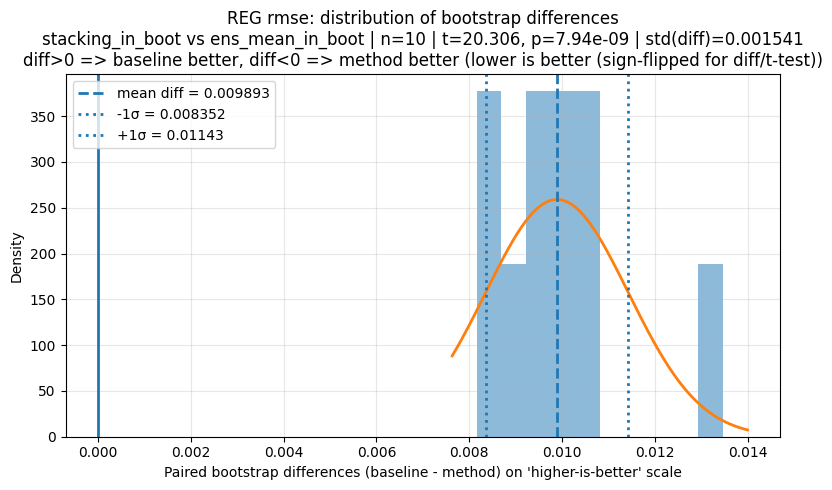

RAW mean(stacking_in_boot) = 0.127845
RAW mean(ens_mean_in_boot)   = 0.137737
DIFF mean(baseline-method, hi-scale) = 0.00989257
DIFF std (hi-scale) = 0.00154056
paired t-test: t=20.306274, p=7.94021e-09


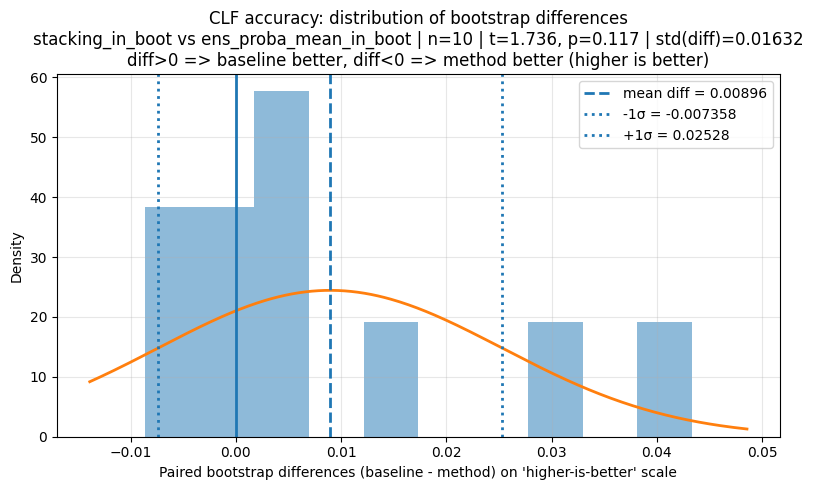

RAW mean(stacking_in_boot) = 0.634682
RAW mean(ens_proba_mean_in_boot)   = 0.625723
DIFF mean(baseline-method, hi-scale) = 0.00895954
DIFF std (hi-scale) = 0.016318
paired t-test: t=1.736272, p=0.116532


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, ttest_rel

def plot_bootstrap_diff_distribution(
    metrics_by_boot: dict,
    baseline: str,
    method: str,
    metric: str,
    higher_is_better: dict,
    bins: int = 12,
    title_prefix: str = "",
):
    """
    Plot distribution of paired bootstrap differences: (baseline - method)
    computed on a scale where "higher is better".

    - If metric is lower-is-better (rmse/mae/log_loss), we sign-flip both values
      before computing differences, so:
          diff > 0  => baseline better
          diff < 0  => method better

    This is the plot your teammate likely showed: a histogram that often looks
    roughly normal (CLT-ish) if you have enough bootstraps.
    """
    boots = sorted(metrics_by_boot.keys())

    base_vals_hi = []
    meth_vals_hi = []
    base_vals_raw = []
    meth_vals_raw = []

    for b in boots:
        if baseline not in metrics_by_boot[b]:
            continue
        if method not in metrics_by_boot[b]:
            continue
        if metric not in metrics_by_boot[b][baseline]:
            continue
        if metric not in metrics_by_boot[b][method]:
            continue

        a_raw = float(metrics_by_boot[b][baseline][metric])
        m_raw = float(metrics_by_boot[b][method][metric])

        a_hi = a_raw
        m_hi = m_raw
        if not higher_is_better.get(metric, True):
            a_hi = -a_hi
            m_hi = -m_hi

        base_vals_raw.append(a_raw)
        meth_vals_raw.append(m_raw)
        base_vals_hi.append(a_hi)
        meth_vals_hi.append(m_hi)

    base_vals_hi = np.asarray(base_vals_hi, dtype=float)
    meth_vals_hi = np.asarray(meth_vals_hi, dtype=float)
    base_vals_raw = np.asarray(base_vals_raw, dtype=float)
    meth_vals_raw = np.asarray(meth_vals_raw, dtype=float)

    n = len(base_vals_hi)
    if n < 2:
        print(f"Not enough paired bootstrap points for distribution plot: n={n}")
        return

    diffs = base_vals_hi - meth_vals_hi  # >0 => baseline better
    mu = float(np.mean(diffs))
    sigma = float(np.std(diffs, ddof=1)) if n > 1 else float("nan")

    # Paired t-test on HI scale
    t_stat, p_val = ttest_rel(base_vals_hi, meth_vals_hi, nan_policy="omit")

    # ---- Histogram of differences ----
    plt.figure(figsize=(8, 5))
    counts, edges, _ = plt.hist(diffs, bins=bins, density=True, alpha=0.5)

    # Overlay fitted normal curve (if sigma > 0)
    x_min, x_max = float(np.min(diffs)), float(np.max(diffs))
    pad = 0.1 * (x_max - x_min) if x_max > x_min else 1.0
    xs = np.linspace(x_min - pad, x_max + pad, 300)

    if np.isfinite(sigma) and sigma > 0:
        ys = norm.pdf(xs, loc=mu, scale=sigma)
        plt.plot(xs, ys, linewidth=2)

    # Mean and ±1 std markers
    plt.axvline(mu, linestyle="--", linewidth=2, label=f"mean diff = {mu:.4g}")
    if np.isfinite(sigma) and sigma > 0:
        plt.axvline(mu - sigma, linestyle=":", linewidth=2, label=f"-1σ = {(mu - sigma):.4g}")
        plt.axvline(mu + sigma, linestyle=":", linewidth=2, label=f"+1σ = {(mu + sigma):.4g}")

    # Interpretation helper line at 0 (no difference)
    plt.axvline(0.0, linewidth=2)
    plt.xlabel(f"Paired bootstrap differences (baseline - method) on 'higher-is-better' scale")
    plt.ylabel("Density")

    hib = higher_is_better.get(metric, True)
    direction_note = "higher is better" if hib else "lower is better (sign-flipped for diff/t-test)"

    plt.title(
        f"{title_prefix}{metric}: distribution of bootstrap differences\n"
        f"{baseline} vs {method} | n={n} | t={t_stat:.3f}, p={p_val:.3g} | std(diff)={sigma:.4g}\n"
        f"diff>0 => baseline better, diff<0 => method better ({direction_note})"
    )
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Extra: print raw means too (more intuitive)
    print(f"RAW mean({baseline}) = {float(np.mean(base_vals_raw)):.6g}")
    print(f"RAW mean({method})   = {float(np.mean(meth_vals_raw)):.6g}")
    print(f"DIFF mean(baseline-method, hi-scale) = {mu:.6g}")
    print(f"DIFF std (hi-scale) = {sigma:.6g}")
    print(f"paired t-test: t={t_stat:.6f}, p={p_val:.6g}")


# -----------------------------
# Examples (edit these two lines)
# -----------------------------

# Regression: stacking vs mean-ensemble
reg_higher_is_better = {"r2": True, "rmse": False, "mae": False}
plot_bootstrap_diff_distribution(
    metrics_by_boot=reg_metrics_by_boot,
    baseline="stacking_in_boot",
    method="ens_mean_in_boot",
    metric="rmse",
    higher_is_better=reg_higher_is_better,
    bins=10,
    title_prefix="REG ",
)

# Classification: stacking vs proba-mean ensemble
clf_higher_is_better = {
    "accuracy": True,
    "balanced_accuracy": True,
    "macro_f1": True,
    "weighted_f1": True,
    "log_loss": False
}
plot_bootstrap_diff_distribution(
    metrics_by_boot=clf_metrics_by_boot,
    baseline="stacking_in_boot",
    method="ens_proba_mean_in_boot",
    metric="accuracy",
    higher_is_better=clf_higher_is_better,
    bins=10,
    title_prefix="CLF ",
)

### Final Comparison

In [44]:
import pandas as pd

def align_X_create_interactions(X, meta):
    """
    Align DataFrame columns to meta['feature_cols'].
    If some expected columns are missing and look like interaction features
    in the form 'colA_x_colB', attempt to create them as X[colA] * X[colB].
    """
    if meta is None:
        return X
    feat_cols = meta.get("feature_cols", None)
    if feat_cols is None:
        return X

    if not isinstance(X, pd.DataFrame):
        # can't auto-create named features if it's already numpy
        return X

    # Create interaction terms if needed
    missing = [c for c in feat_cols if c not in X.columns]
    created = []

    for col in missing:
        if "_x_" in col:
            left, right = col.split("_x_", 1)
            if left in X.columns and right in X.columns:
                X[col] = X[left] * X[right]
                created.append(col)

    # Recompute missing after attempted creation
    missing = [c for c in feat_cols if c not in X.columns]
    if missing:
        raise ValueError(
            "X is still missing expected columns after creating interactions.\n"
            f"First 15 missing: {missing[:15]}\n\n"
            "This usually means champion used feature engineering that A5 doesn't reproduce "
            "(e.g., polynomial features, one-hot categories, scaling pipeline, or different naming)."
        )

    # Return aligned feature order
    return X[feat_cols]

In [46]:
import os, glob, json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, balanced_accuracy_score, f1_score, log_loss
)
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone


# ---------------------------
# Helpers
# ---------------------------

def load_meta(dir_path):
    meta_candidates = glob.glob(os.path.join(dir_path, "*meta*.json"))
    if not meta_candidates:
        return None
    with open(meta_candidates[0], "r") as f:
        return json.load(f)

def align_X(X, meta):
    """
    Align DataFrame columns to meta['feature_cols'] if present.
    If X is numpy array or no meta, return X unchanged.
    """
    if meta is None:
        return X
    feat_cols = meta.get("feature_cols", None)
    if feat_cols is None:
        return X
    if isinstance(X, pd.DataFrame):
        missing = [c for c in feat_cols if c not in X.columns]
        if missing:
            raise ValueError(f"X is missing expected columns (first 10): {missing[:10]}")
        return X[feat_cols]
    return X

import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def regression_row(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)   # no squared=...
    rmse = float(np.sqrt(mse))
    return {
        "method": name,
        "R2": float(r2_score(y_true, y_pred)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse,
    }

def classification_row(name, y_true, y_pred, proba=None, classes=None):
    row = {
        "method": name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted")),
    }
    if proba is not None:
        try:
            row["log_loss"] = float(log_loss(y_true, proba, labels=classes))
        except Exception:
            pass
    return row

def mean_reg(pred_list):
    return np.mean(np.vstack(pred_list), axis=0)

def mean_proba(proba_list):
    return np.mean(np.stack(proba_list, axis=0), axis=0)

def predict_reg(model_or_list, X):
    if isinstance(model_or_list, (list, tuple)):
        return mean_reg([m.predict(X) for m in model_or_list])
    return model_or_list.predict(X)

def predict_proba(model_or_list, X):
    if isinstance(model_or_list, (list, tuple)):
        probas = [m.predict_proba(X) for m in model_or_list]
        proba = mean_proba(probas)
        classes = getattr(model_or_list[0], "classes_", None)
        return proba, classes
    proba = model_or_list.predict_proba(X)
    classes = getattr(model_or_list, "classes_", None)
    return proba, classes


# ---------------------------
# Load champion artifacts explicitly
# ---------------------------

score_dir = "../../../trained_models/score_model"
weakest_dir = "../../../trained_models/weakest_link_model"

score_meta = load_meta(score_dir)
weakest_meta = load_meta(weakest_dir)

score_model = joblib.load(os.path.join(score_dir, "champion_model.pkl"))   # explicit
weakest_model = joblib.load(os.path.join(weakest_dir, "champion_model.joblib"))  # explicit

print("Loaded regression champion:", type(score_model))
print("Loaded classification champion:", type(weakest_model))


# =====================================================
# REGRESSION LEADERBOARD
# Requires: X_test_r, y_test_r
# Optionally: yhat_global_mean OR all_test_preds_r
# Optionally: stack_r or REG_stacking
# =====================================================

X_test_r_aligned = align_X_create_interactions(X_test_r.copy(), score_meta)

reg_rows = []
yhat_score = predict_reg(score_model, X_test_r_aligned)
reg_rows.append(regression_row("champion_score_model", y_test_r, yhat_score))

if "yhat_global_mean" in globals():
    reg_rows.append(regression_row("bootstrap+hetero_global_mean", y_test_r, yhat_global_mean))
elif "all_test_preds_r" in globals():
    reg_rows.append(regression_row("bootstrap+hetero_global_mean", y_test_r, mean_reg(all_test_preds_r)))

if "stack_r" in globals():
    reg_rows.append(regression_row("stacking_full_train", y_test_r, stack_r.predict(X_test_r)))
elif "REG_stacking" in globals():
    reg_rows.append(regression_row("stacking_full_train", y_test_r, REG_stacking.predict(X_test_r)))

df_reg = pd.DataFrame(reg_rows).sort_values(["RMSE", "MAE"], ascending=True).reset_index(drop=True)
print("\n=== REGRESSION LEADERBOARD (lower RMSE/MAE is better) ===")
display(df_reg)


# =====================================================
# CLASSIFICATION LEADERBOARD
# Requires: X_test_c, y_test_c, X_train_c, y_train_c
# Optionally: proba_global_mean OR all_test_proba_c AND classes_clf
# Optionally: classifiers dict for full-train stacking
# =====================================================

X_test_c_aligned = align_X(X_test_c, weakest_meta)
X_train_c_aligned = align_X(X_train_c, weakest_meta)

clf_rows = []

proba_w, classes_w = predict_proba(weakest_model, X_test_c_aligned)
yhat_w = classes_w[np.argmax(proba_w, axis=1)] if classes_w is not None else np.argmax(proba_w, axis=1)

clf_rows.append(classification_row(
    "champion_weakest_link_model",
    y_test_c,
    yhat_w,
    proba=proba_w,
    classes=classes_w
))

if "proba_global_mean" in globals() and "classes_clf" in globals():
    yhat = classes_clf[np.argmax(proba_global_mean, axis=1)]
    clf_rows.append(classification_row(
        "bootstrap+hetero_global_proba_mean",
        y_test_c,
        yhat,
        proba=proba_global_mean,
        classes=classes_clf
    ))
elif "all_test_proba_c" in globals() and "classes_clf" in globals():
    proba = mean_proba(all_test_proba_c)
    yhat = classes_clf[np.argmax(proba, axis=1)]
    clf_rows.append(classification_row(
        "bootstrap+hetero_global_proba_mean",
        y_test_c,
        yhat,
        proba=proba,
        classes=classes_clf
    ))

# Full-train stacking for a fair single "deployable" stacked model
if "classifiers" in globals():
    estimators_c = [(name, clone(model)) for name, model in classifiers.items()]
    stack_c_full = StackingClassifier(
        estimators=estimators_c,
        final_estimator=LogisticRegression(max_iter=2000),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=-1,
        stack_method="predict_proba",
        passthrough=False
    )
    stack_c_full.fit(X_train_c_aligned, y_train_c)

    proba_stack = stack_c_full.predict_proba(X_test_c_aligned)
    yhat_stack = stack_c_full.classes_[np.argmax(proba_stack, axis=1)]
    clf_rows.append(classification_row(
        "stacking_full_train",
        y_test_c,
        yhat_stack,
        proba=proba_stack,
        classes=stack_c_full.classes_
    ))

df_clf = pd.DataFrame(clf_rows).sort_values(["accuracy", "macro_f1"], ascending=False).reset_index(drop=True)
print("\n=== CLASSIFICATION LEADERBOARD (higher accuracy/F1 is better; lower log_loss is better) ===")
display(df_clf)

Loaded regression champion: <class 'sklearn.linear_model._base.LinearRegression'>
Loaded classification champion: <class 'sklearn.pipeline.Pipeline'>

=== REGRESSION LEADERBOARD (lower RMSE/MAE is better) ===


,method,R2,MAE,RMSE
0,bootstrap+hetero_global_mean,0.732839,0.093981,0.126299
1,stacking_full_train,0.728356,0.091118,0.127354
2,champion_score_model,0.641204,0.111177,0.146365


c:\Users\kimwo\software engineering\year 4\LP3\4DT907 - Project\machine_learning_project_4dt907\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



=== CLASSIFICATION LEADERBOARD (higher accuracy/F1 is better; lower log_loss is better) ===


,method,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss
0,stacking_full_train,0.673410,0.470563,0.464854,0.654829,0.989950
1,bootstrap+hetero_global_proba_mean,0.650289,0.473645,0.470636,0.638245,1.014363
2,champion_weakest_link_model,0.589595,0.494525,0.411950,0.594655,NaN


### Statistical confidence for Regression (RMSE + MAE)

In [48]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ---------- configure ----------
N_BOOT = 2000   # increase for tighter CI (e.g., 5000) if runtime allows
SEED = 42
rng = np.random.default_rng(SEED)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def bootstrap_ci(diff_samples, alpha=0.05):
    lo = np.quantile(diff_samples, alpha/2)
    hi = np.quantile(diff_samples, 1 - alpha/2)
    return float(lo), float(hi)

# ---------- gather regression predictions ----------
# expects you already computed these in your leaderboard cell:
# yhat_score (champion regression)
# plus one or both:
# yhat_global_mean OR mean_reg(all_test_preds_r)
# and stacking: stack_r or REG_stacking

y_true = np.asarray(y_test_r)

preds = {
    "champion_score_model": np.asarray(yhat_score),
}

if "yhat_global_mean" in globals():
    preds["bootstrap+hetero_global_mean"] = np.asarray(yhat_global_mean)
elif "all_test_preds_r" in globals():
    preds["bootstrap+hetero_global_mean"] = np.asarray(mean_reg(all_test_preds_r))

if "stack_r" in globals():
    preds["stacking_full_train"] = np.asarray(stack_r.predict(X_test_r))
elif "REG_stacking" in globals():
    preds["stacking_full_train"] = np.asarray(REG_stacking.predict(X_test_r))

# ---------- bootstrap test set to compare against champion ----------
n = len(y_true)
idx = np.arange(n)

baseline_name = "champion_score_model"
baseline_pred = preds[baseline_name]

rows = []
for method, y_pred in preds.items():
    if method == baseline_name:
        continue

    # store delta metric over bootstrap resamples (method - champion)
    delta_rmse = np.empty(N_BOOT, dtype=float)
    delta_mae  = np.empty(N_BOOT, dtype=float)

    for b in range(N_BOOT):
        s = rng.choice(idx, size=n, replace=True)
        y_s = y_true[s]
        base_s = baseline_pred[s]
        meth_s = y_pred[s]

        # improvements should be NEGATIVE for RMSE/MAE if better
        delta_rmse[b] = rmse(y_s, meth_s) - rmse(y_s, base_s)
        delta_mae[b]  = mean_absolute_error(y_s, meth_s) - mean_absolute_error(y_s, base_s)

    # CI for deltas
    rmse_ci = bootstrap_ci(delta_rmse)
    mae_ci  = bootstrap_ci(delta_mae)

    # one-sided p-value for "method better than champion"
    # better means delta < 0
    p_rmse = float(np.mean(delta_rmse >= 0))
    p_mae  = float(np.mean(delta_mae >= 0))

    rows.append({
        "method_vs_champion": method,
        "ΔRMSE_mean (method-champ)": float(np.mean(delta_rmse)),
        "ΔRMSE_95%CI_low": rmse_ci[0],
        "ΔRMSE_95%CI_high": rmse_ci[1],
        "RMSE_win_rate": float(np.mean(delta_rmse < 0)),
        "RMSE_p_one_sided": p_rmse,

        "ΔMAE_mean (method-champ)": float(np.mean(delta_mae)),
        "ΔMAE_95%CI_low": mae_ci[0],
        "ΔMAE_95%CI_high": mae_ci[1],
        "MAE_win_rate": float(np.mean(delta_mae < 0)),
        "MAE_p_one_sided": p_mae,
    })

df_reg_ci = pd.DataFrame(rows).sort_values("ΔRMSE_mean (method-champ)")
print(f"Regression test-set bootstrap: N_BOOT={N_BOOT}")
print("Interpretation: negative Δ means improvement over champion.")
display(df_reg_ci)

Regression test-set bootstrap: N_BOOT=2000
Interpretation: negative Δ means improvement over champion.


,method_vs_champion,ΔRMSE_mean (method-champ),ΔRMSE_95%CI_low,ΔRMSE_95%CI_high,RMSE_win_rate,RMSE_p_one_sided,ΔMAE_mean (method-champ),ΔMAE_95%CI_low,ΔMAE_95%CI_high,MAE_win_rate,MAE_p_one_sided
0,bootstrap+hetero_global_mean,-0.020022,-0.025349,-0.014442,1.000,0.000,-0.017149,-0.021409,-0.012744,1.0,0.0
1,stacking_full_train,-0.019028,-0.029014,-0.008873,0.999,0.001,-0.020079,-0.026905,-0.012606,1.0,0.0


### Statistical confidence for Classification (Accuracy + Macro-F1 + Log-loss)

In [49]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, log_loss

# ---------- configure ----------
N_BOOT = 2000
SEED = 42
rng = np.random.default_rng(SEED)

def bootstrap_ci(samples, alpha=0.05):
    lo = np.quantile(samples, alpha/2)
    hi = np.quantile(samples, 1 - alpha/2)
    return float(lo), float(hi)

# ---------- gather classification predictions/probas ----------
# expects your leaderboard cell computed:
# proba_w, classes_w (champion classification)
# and optionally:
# proba_global_mean, classes_clf OR all_test_proba_c
# and optionally: stack_c_full (if you created it), otherwise we re-fit here is NOT ideal.
# We'll use what exists.

y_true = np.asarray(y_test_c)
n = len(y_true)
idx = np.arange(n)

# champion
baseline_name = "champion_weakest_link_model"
probas = {baseline_name: np.asarray(proba_w)}
classes = {baseline_name: classes_w}

# bootstrap+hetero
if "proba_global_mean" in globals() and "classes_clf" in globals():
    probas["bootstrap+hetero_global_proba_mean"] = np.asarray(proba_global_mean)
    classes["bootstrap+hetero_global_proba_mean"] = classes_clf
elif "all_test_proba_c" in globals() and "classes_clf" in globals():
    probas["bootstrap+hetero_global_proba_mean"] = np.asarray(mean_proba(all_test_proba_c))
    classes["bootstrap+hetero_global_proba_mean"] = classes_clf

# stacking_full_train (if it exists from your leaderboard cell)
# If you named it differently, adjust here.
if "proba_stack" in globals() and "stack_c_full" in globals():
    probas["stacking_full_train"] = np.asarray(proba_stack)
    classes["stacking_full_train"] = stack_c_full.classes_

def labels_from_proba(proba, cls):
    if cls is None:
        return np.argmax(proba, axis=1)
    return cls[np.argmax(proba, axis=1)]

# ---------- bootstrap test set to compare against champion ----------
base_proba = probas[baseline_name]
base_cls = classes[baseline_name]
base_pred = labels_from_proba(base_proba, base_cls)

rows = []
for method in probas.keys():
    if method == baseline_name:
        continue

    meth_proba = probas[method]
    meth_cls = classes[method]
    meth_pred = labels_from_proba(meth_proba, meth_cls)

    # deltas: (method - champion)
    delta_acc = np.empty(N_BOOT, dtype=float)
    delta_f1  = np.empty(N_BOOT, dtype=float)
    delta_ll  = np.empty(N_BOOT, dtype=float)

    for b in range(N_BOOT):
        s = rng.choice(idx, size=n, replace=True)
        y_s = y_true[s]

        # label metrics
        delta_acc[b] = accuracy_score(y_s, meth_pred[s]) - accuracy_score(y_s, base_pred[s])
        delta_f1[b]  = f1_score(y_s, meth_pred[s], average="macro") - f1_score(y_s, base_pred[s], average="macro")

        # log loss (lower is better) — only valid if class labels align
        # We try; if it fails, store NaN and ignore in summary.
        try:
            delta_ll[b] = log_loss(y_s, meth_proba[s], labels=meth_cls) - log_loss(y_s, base_proba[s], labels=base_cls)
        except Exception:
            delta_ll[b] = np.nan

    # CIs
    acc_ci = bootstrap_ci(delta_acc)
    f1_ci  = bootstrap_ci(delta_f1)

    # one-sided p-values for "method better"
    # better means delta_acc > 0 and delta_f1 > 0
    p_acc = float(np.mean(delta_acc <= 0))
    p_f1  = float(np.mean(delta_f1 <= 0))

    # for log loss: better means delta_ll < 0
    ll_valid = delta_ll[~np.isnan(delta_ll)]
    if len(ll_valid) > 0:
        ll_ci = bootstrap_ci(ll_valid)
        p_ll = float(np.mean(ll_valid >= 0))
        ll_mean = float(np.mean(ll_valid))
        ll_win = float(np.mean(ll_valid < 0))
    else:
        ll_ci = (np.nan, np.nan)
        p_ll = np.nan
        ll_mean = np.nan
        ll_win = np.nan

    rows.append({
        "method_vs_champion": method,

        "ΔACC_mean": float(np.mean(delta_acc)),
        "ΔACC_95%CI_low": acc_ci[0],
        "ΔACC_95%CI_high": acc_ci[1],
        "ACC_win_rate": float(np.mean(delta_acc > 0)),
        "ACC_p_one_sided": p_acc,

        "ΔMacroF1_mean": float(np.mean(delta_f1)),
        "ΔMacroF1_95%CI_low": f1_ci[0],
        "ΔMacroF1_95%CI_high": f1_ci[1],
        "MacroF1_win_rate": float(np.mean(delta_f1 > 0)),
        "MacroF1_p_one_sided": p_f1,

        "ΔLogLoss_mean (method-champ)": ll_mean,
        "ΔLogLoss_95%CI_low": ll_ci[0],
        "ΔLogLoss_95%CI_high": ll_ci[1],
        "LogLoss_win_rate": ll_win,
        "LogLoss_p_one_sided": p_ll,
    })

df_clf_ci = pd.DataFrame(rows).sort_values("ΔACC_mean", ascending=False)
print(f"Classification test-set bootstrap: N_BOOT={N_BOOT}")
print("Interpretation: positive ΔACC/ΔF1 means improvement; negative ΔLogLoss means improvement.")
display(df_clf_ci)

Classification test-set bootstrap: N_BOOT=2000
Interpretation: positive ΔACC/ΔF1 means improvement; negative ΔLogLoss means improvement.


,method_vs_champion,ΔACC_mean,ΔACC_95%CI_low,ΔACC_95%CI_high,ACC_win_rate,ACC_p_one_sided,ΔMacroF1_mean,ΔMacroF1_95%CI_low,ΔMacroF1_95%CI_high,MacroF1_win_rate,MacroF1_p_one_sided,ΔLogLoss_mean (method-champ),ΔLogLoss_95%CI_low,ΔLogLoss_95%CI_high,LogLoss_win_rate,LogLoss_p_one_sided
1,stacking_full_train,0.083792,0.037500,0.132948,0.9995,0.0005,0.044327,-0.030198,0.113761,0.8875,0.1125,-0.175026,-0.308379,-0.064004,1.000000,0.000000
0,bootstrap+hetero_global_proba_mean,0.060858,0.014451,0.104118,0.9925,0.0075,0.049342,-0.014278,0.109213,0.9300,0.0700,-0.157628,-0.270213,-0.051647,0.997226,0.002774
